# Módulo 5 — Textura (GLCM) y criterio D

| | |
|---|---|
| **Responde** | Extracción de características (texturas) · metodología 6 |
| **Código** | `textura_criterio_d.py` (en esta misma carpeta) |
| **Recibe** | el canal V de la imagen mejorada y la máscara |
| **Devuelve** | atributos GLCM; D estimado (0-5) |
| **Responsable** | _completar_ |

> Las funciones se programan en `textura_criterio_d.py`. Este cuaderno sólo las llama, grafica y discute.
> Para guardar una figura para el informe: `graficos.guardar_figura(fig, "nombre")`.
> Para comprobar el módulo: `python main.py --revisar` desde la carpeta del repo.

In [1]:
# Permite usar el código de las otras carpetas del repo
import sys
sys.path.insert(0, "../..")

# Recarga los cambios que hagas en los archivos .py sin reiniciar el cuaderno
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

import pandas as pd
from modulos.m0_carga_de_datos import carga_de_datos
from modulos.m1_mejoramiento import mejoramiento
from modulos.m5_textura_criterio_d import textura_criterio_d
from modulos.herramientas import graficos, lesion_de_prueba
from modulos.herramientas.procesamiento_completo import procesar, procesar_todos

graficos.aplicar_estilo()

## Prueba con lesiones inventadas: lisa vs. con red

In [2]:
lisa, info = lesion_de_prueba.generar_lesion(semilla=7, textura=0)
rugosa, _ = lesion_de_prueba.generar_lesion(semilla=7, textura=0.6)
v = lambda x: mejoramiento.a_hsv(x)[..., 2]
pd.DataFrame([textura_criterio_d.atributos_glcm(v(lisa), info["mascara"]),
              textura_criterio_d.atributos_glcm(v(rugosa), info["mascara"])], index=["lisa", "rugosa"]).round(3)

,energia,entropia,contraste,idm,correlacion,cluster_shade,cluster_prominence
lisa,0.060,4.729,0.508,0.796,0.972,51.149,2612.647
rugosa,0.032,5.859,9.799,0.705,0.794,-124.493,15313.043


## 1. Atributos GLCM en PH2 (entrenamiento)

- [x] Justificar `NIVELES` y `DISTANCIA` (probar 2 o 3 valores).
- [x] Boxplots de cada atributo por diagnóstico y por D del dermatólogo.

**Ojo:** M3 todavía no está, así que acá se usa la **máscara de referencia** de PH2. Cuando M3 esté en `main`, hay que volver a correr este cuaderno con la máscara automática; `completar_d` ya ajusta con la tabla real de `main.py`.

In [3]:
from scipy import stats

filas = []
for nombre in carga_de_datos.nombres("entrenamiento"):
    caso = carga_de_datos.cargar_caso(nombre)
    img, _, _ = mejoramiento.mejorar(caso.imagen)
    v = mejoramiento.a_hsv(img)[..., 2]
    fila = {"nombre": nombre, "D_derm": caso.d_dermatologo, "diagnostico": caso.diagnostico, "sospechosa": caso.sospechosa}
    for niveles in (8, 16, 32, 64):
        for distancia in (1, 2, 4):
            for k, x in textura_criterio_d.atributos_glcm(v, caso.mascara_ref, distancia, niveles).items():
                fila[f"{niveles}_{distancia}_{k}"] = x
    filas.append(fila)
exploracion = pd.DataFrame(filas)

# Spearman de cada atributo con D para cada combinación de niveles y distancia
rho = pd.DataFrame({f"{n} niveles, d = {d}": {k: stats.spearmanr(exploracion[f"{n}_{d}_{k}"], exploracion["D_derm"]).statistic
                                              for k in textura_criterio_d.ATRIBUTOS}
                    for n in (8, 16, 32, 64) for d in (1, 2, 4)}).T
rho.round(3)

,energia,entropia,contraste,idm,correlacion,cluster_shade,cluster_prominence
"8 niveles, d = 1",-0.323,0.359,-0.045,0.064,0.439,0.170,0.432
"8 niveles, d = 2",-0.311,0.358,-0.057,0.085,0.445,0.168,0.433
"8 niveles, d = 4",-0.302,0.360,0.034,0.033,0.435,0.164,0.432
"16 niveles, d = 1",-0.282,0.325,-0.072,0.145,0.443,0.159,0.426
"16 niveles, d = 2",-0.272,0.319,-0.067,0.163,0.448,0.158,0.426
"16 niveles, d = 4",-0.263,0.321,0.047,0.072,0.430,0.153,0.426
"32 niveles, d = 1",-0.257,0.295,-0.069,0.132,0.451,0.153,0.427
"32 niveles, d = 2",-0.246,0.283,-0.067,0.153,0.456,0.152,0.426
"32 niveles, d = 4",-0.231,0.298,0.049,0.078,0.426,0.150,0.427
"64 niveles, d = 1",-0.249,0.272,-0.072,0.126,0.451,0.151,0.427


**Resultado:** ni `NIVELES` ni `DISTANCIA` cambian mucho lo que importa. El mejor atributo (`correlacion`) queda entre 0,44 y 0,46 en todas las combinaciones. Se deja **32 niveles** (conserva detalle sin que la matriz de 32 × 32 quede casi vacía) y **distancia 1** (la más simple, y no pierde nada).

**Lo que sorprende:** `contraste`, el atributo que uno elegiría por intuición, casi no se relaciona con D (ρ ≈ −0,07). Lo que sigue a D es `correlacion` y `cluster_prominence`. Una lectura posible, que falta confirmar, es que miden más la heterogeneidad a escala grande (regiones claras y oscuras) que la rugosidad fina.

PosixPath('/Users/lucasdelia/Desktop/7mo Cuatri ITBA /16.63 - Procesamiento de Señales e Imágenes Biomédicas/TPF/TPI/PSIB2026Q2-TPI-Grupo02-CassanoNieto-DElia-Ortega/informe/figuras/m5_atributos.pdf')

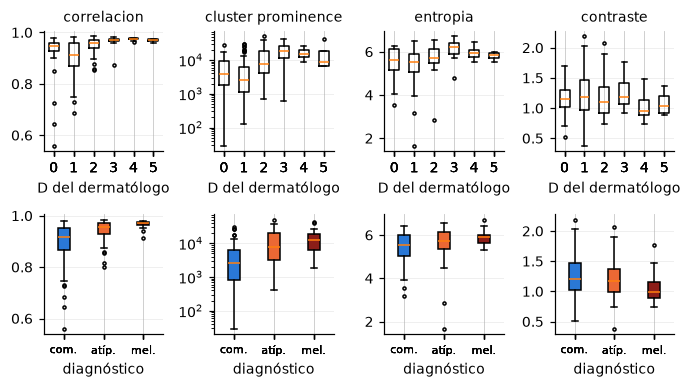

In [4]:
# Tabla con los parámetros elegidos, con las columnas que usa elegir_atributo_d
tabla = exploracion[["nombre", "D_derm", "diagnostico", "sospechosa"]].copy()
for k in textura_criterio_d.ATRIBUTOS:
    tabla[f"glcm_{k}"] = exploracion[f"{textura_criterio_d.NIVELES}_{textura_criterio_d.DISTANCIA}_{k}"]

mostrar = ["correlacion", "cluster_prominence", "entropia", "contraste"]
fig, ax = plt.subplots(2, 4, figsize=(6.3, 3.6), sharex="row")
for a, k in zip(ax[0], mostrar):
    a.boxplot([tabla.loc[tabla["D_derm"] == d, f"glcm_{k}"] for d in range(6)], tick_labels=range(6), flierprops={"markersize": 2})
    a.set_title(k.replace("_", " ")); a.set_xlabel("D del dermatólogo")
    if k == "cluster_prominence": a.set_yscale("log")
for a, k in zip(ax[1], mostrar):
    cajas = a.boxplot([tabla.loc[tabla["diagnostico"] == d, f"glcm_{k}"] for d in range(3)], tick_labels=["com.", "atíp.", "mel."],
                      patch_artist=True, flierprops={"markersize": 2})
    for caja, d in zip(cajas["boxes"], range(3)):
        caja.set_facecolor(graficos.COLOR_DIAGNOSTICO[d])
    a.tick_params(axis="x", labelsize=7); a.set_xlabel("diagnóstico")
    if k == "cluster_prominence": a.set_yscale("log")
fig.tight_layout()
graficos.guardar_figura(fig, "m5_atributos")

## 2. Criterio D adaptado

- [x] Elegir el atributo (`elegir_atributo_d`) y los umbrales; acuerdo con el D del dermatólogo.
- [x] Discutir la limitación: un solo atributo global para cinco estructuras distintas (y cómo lo mejora M6).

Se comparan dos formas de poner los umbrales, con **validación cruzada dentro de entrenamiento** (4 partes, 20 repeticiones) para no medir sobre las mismas imágenes con las que se ajusta:
- **medianas:** puntos medios entre las medianas de cada D (lo que sugería el esqueleto).
- **cuantiles:** umbrales que reparten el D estimado como el del dermatólogo (lo que quedó en `ajustar_umbrales_d`).

In [5]:
from sklearn.metrics import cohen_kappa_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold

print(textura_criterio_d.correlaciones_con_d(tabla).round(3).to_string())
columna = textura_criterio_d.elegir_atributo_d(tabla)
print("\nElegido:", columna)

def umbrales_medianas(x, d):
    presentes = np.unique(d)
    medianas = np.maximum.accumulate([np.median(x[d == k]) for k in presentes])
    medianas = np.interp(np.arange(presentes.max() + 1), presentes, medianas)
    return (medianas[:-1] + medianas[1:]) / 2

x, y, sospechosa = tabla[columna].to_numpy(), tabla["D_derm"].to_numpy(), tabla["sospechosa"].to_numpy()
filas = []
for metodo, ajustar in (("medianas", umbrales_medianas), ("cuantiles", textura_criterio_d.ajustar_umbrales_d)):
    for semilla in range(20):
        estimado = np.zeros(len(y), int)
        for a, b in StratifiedKFold(4, shuffle=True, random_state=semilla).split(x, np.minimum(y, 3)):
            u = ajustar(x[a], y[a])
            estimado[b] = [textura_criterio_d.estimar_d(valor, u) for valor in x[b]]
        filas.append({"umbrales": metodo, "acierto exacto": (estimado == y).mean(), "error medio": np.abs(estimado - y).mean(),
                      "D estimado = 5": (estimado == 5).sum(), "kappa": cohen_kappa_score(estimado, y),
                      "AUC sospechosa": roc_auc_score(sospechosa, estimado)})
comparacion = pd.DataFrame(filas).groupby("umbrales").mean().round(3)
referencia = {"acierto exacto": (y == np.median(y)).mean(), "error medio": np.abs(y - np.median(y)).mean()}
print("\nReferencia, decir siempre la mediana:", {k: round(float(v), 3) for k, v in referencia.items()})
print("D del dermatólogo (real) con estas imágenes: AUC sospechosa =", round(roc_auc_score(sospechosa, y), 3))
comparacion

glcm_correlacion           0.451
glcm_cluster_prominence    0.427
glcm_entropia              0.295
glcm_cluster_shade         0.153
glcm_idm                   0.132
glcm_contraste            -0.069
glcm_energia              -0.257

Elegido: glcm_correlacion

Referencia, decir siempre la mediana: {'acierto exacto': 0.371, 'error medio': 0.921}
D del dermatólogo (real) con estas imágenes: AUC sospechosa = 0.924


,acierto exacto,error medio,D estimado = 5,kappa,AUC sospechosa
umbrales,,,,,
cuantiles,0.319,0.971,5.25,0.084,0.748
medianas,0.198,1.308,20.25,0.045,0.732


In [6]:
# Tabla para el informe y comparación final, ajustando con todo entrenamiento
umbrales = textura_criterio_d.ajustar_umbrales_d(x, y)
estimado = np.array([textura_criterio_d.estimar_d(valor, umbrales) for valor in x])
print("Umbrales sobre", columna, np.round(umbrales, 4))
graficos.guardar_tabla(comparacion.reset_index(), "m5_umbrales_d", decimales=2)
pd.crosstab(pd.Series(y, name="D dermatólogo"), pd.Series(estimado, name="D estimado"))

Umbrales sobre glcm_correlacion [0.884  0.9579 0.9744 0.9778 0.9824]


D estimado,0,1,2,3,4,5
D dermatólogo,,,,,,
0,4,13,5,1,1,0
1,16,23,10,1,2,0
2,3,16,13,3,1,3
3,1,0,6,3,2,1
4,0,0,2,4,2,0
5,0,0,3,1,0,0


**Decisión:** umbrales por **cuantiles** sobre `correlacion`. Con medianas se estimaba D = 5 unas 20 veces, cuando en entrenamiento hay sólo 4 imágenes así; eso infla el TDS sin motivo.

**Limitación que hay que decir en el informe:** el D estimado es **débil como medida de D**. Acierta el valor exacto en cerca de 1 de cada 3 imágenes, no le gana en acierto a decir siempre la mediana (37 %) y su acuerdo con el dermatólogo es casi nulo (κ ≈ 0,08). Es esperable: un solo número global de textura no puede contar cinco estructuras distintas (red, glóbulos, estrías, regresión, velo).

**Lo que sí aporta:** separa sospechosas de comunes (AUC ≈ 0,75), mientras que un D constante no separa nada (AUC 0,5). Aun así queda lejos del D del dermatólogo (AUC 0,92). Por eso conviene evaluar el TDS **también** con los contrastes de M6, que miran *dónde* está cada cosa en vez de un solo número global.

**Una decisión que condiciona a M7:** se elige el atributo que más *crece* con D, porque `completar_d` no le pasa el signo a `estimar_d`. Con estos datos no cambia el resultado: los dos atributos más relacionados ya crecen con D.